# Logistic model fitting and short-horizon forecasts by wave
This notebook fits the continuous logistic model to cumulative cases within a selected wave. It uses a chronological holdout rather than random splitting, because time-series leakage is an impressively common way to make forecasting look better than it is.

**Important:** the forecast is conditional on one-wave logistic assumptions. It is not intended for a multi-wave cumulative curve, and model extrapolation is especially unreliable when the wave has not begun to slow.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

ROOT=Path.cwd()
if not (ROOT/"data/processed/us_covid_all_waves.csv").exists(): ROOT=ROOT.parent

data=pd.read_csv(ROOT/"data/processed/us_covid_all_waves.csv",parse_dates=["week_ending"])

waves=sorted(data.wave.unique())
WAVE_ID=4  # edit to choose a wave

wave=data[data.wave==WAVE_ID].sort_values("week_ending").reset_index(drop=True)

if len(wave)<10: raise ValueError("Selected wave needs >=10 weekly observations")

t=np.arange(len(wave),dtype=float)
P=wave.cumulative_cases_in_wave.to_numpy(float)

if np.any(P<=0) or np.any(np.diff(P)<0): raise ValueError("Wave cumulative data must be positive and nondecreasing")
print("Wave",WAVE_ID,"dates",wave.week_ending.min().date(),"to",wave.week_ending.max().date(),"weeks",len(wave))

Wave 4 dates 2021-11-14 to 2022-04-03 weeks 21


In [ ]:
n_train = max(10, int(0.8 * len(t)))
t_train, t_test = t[:n_train], t[n_train:]
P_train, P_test = P[:n_train], P[n_train:]

def logistic(t, r, K, P0):
        return K / (1.0 + ((K - P0) / P0) * np.exp(-r * t))

init = (0.3, max(P_train.max() * 1.1, P_train[-1] * 1.1), P_train[0])
bounds = (
        [1e-6, P_train.max() * 1.00001, 1e-8],
        [5.0, max(P_train.max() * 100, 1e9), max(P_train[0] * 1.5, P_train[0] + 1.0)]
)

params, cov = curve_fit(
        logistic,
        t_train,
        P_train,
        p0=init,
        bounds=bounds,
        maxfev=30000
)
r_hat, K_hat, P0_hat = params
train_pred = logistic(t_train, *params)
test_pred = logistic(t_test, *params)

metrics = {
        "train_MAE": mean_absolute_error(P_train, train_pred),
        "train_RMSE": mean_squared_error(P_train, train_pred) ** 0.5,
        "train_R2": r2_score(P_train, train_pred),
        "test_MAE": mean_absolute_error(P_test, test_pred),
        "test_RMSE": mean_squared_error(P_test, test_pred) ** 0.5,
        "test_R2": r2_score(P_test, test_pred)
}

print("Parameter estimates:", {"r_per_week": r_hat, "K": K_hat, "P0_fit": P0_hat})
print(pd.Series(metrics))
params,cov=curve_fit(logistic,t_train,P_train,p0=init,bounds=bounds,maxfev=30000)
r_hat,K_hat,P0_hat=params
train_pred=logistic(t_train,*params); test_pred=logistic(t_test,*params)
metrics={"train_MAE":mean_absolute_error(P_train,train_pred),"train_RMSE":mean_squared_error(P_train,train_pred)**.5,"train_R2":r2_score(P_train,train_pred),
         "test_MAE":mean_absolute_error(P_test,test_pred),"test_RMSE":mean_squared_error(P_test,test_pred)**.5,"test_R2":r2_score(P_test,test_pred)}
print("Parameter estimates:",{"r_per_week":r_hat,"K":K_hat,"P0_fit":P0_hat})
print(pd.Series(metrics))


Parameter estimates: {'r_per_week': np.float64(0.43751690959147094), 'K': np.float64(35402655.34547888), 'P0_fit': np.float64(557180.0012637236)}
train_MAE     1.311042e+06
train_RMSE    1.890328e+06
train_R2      9.762520e-01
test_MAE      1.482814e+06
test_RMSE     1.508720e+06
test_R2      -2.566531e+01
dtype: float64
Parameter estimates: {'r_per_week': np.float64(0.43751690959147094), 'K': np.float64(35402655.34547888), 'P0_fit': np.float64(557180.0012637236)}
train_MAE     1.311042e+06
train_RMSE    1.890328e+06
train_R2      9.762520e-01
test_MAE      1.482814e+06
test_RMSE     1.508720e+06
test_R2      -2.566531e+01
dtype: float64


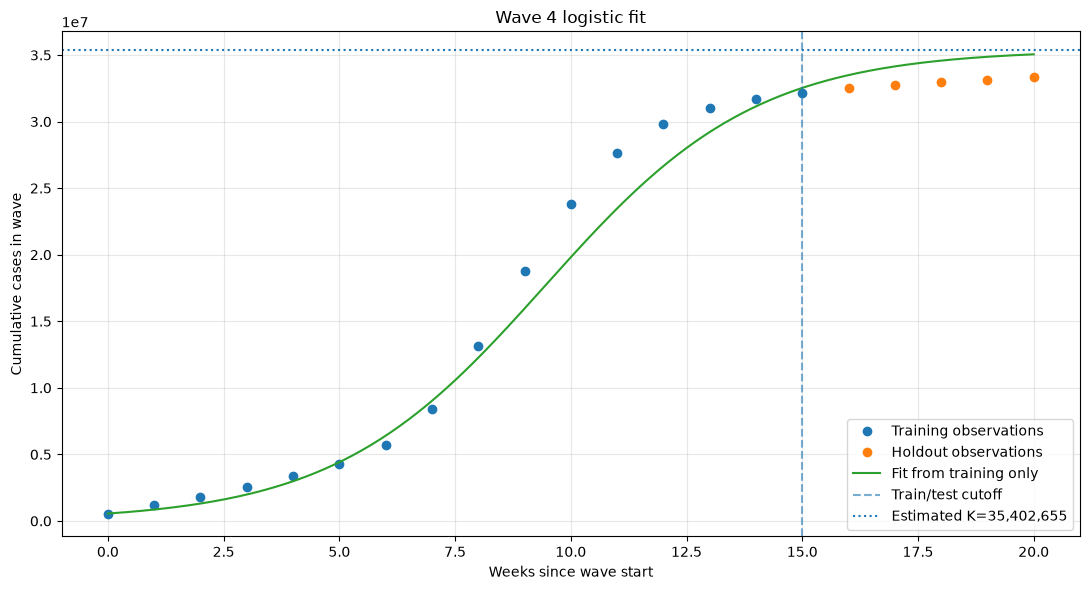

In [5]:
tf=np.linspace(0,t[-1],300)
fig,ax=plt.subplots(figsize=(11,6))
ax.plot(t_train,P_train,"o",label="Training observations")
ax.plot(t_test,P_test,"o",label="Holdout observations")
ax.plot(tf,logistic(tf,*params),label="Fit from training only")
ax.axvline(t_train[-1],ls="--",alpha=.6,label="Train/test cutoff")
ax.axhline(K_hat,ls=":",label=f"Estimated K={K_hat:,.0f}")
ax.set(title=f"Wave {WAVE_ID} logistic fit",xlabel="Weeks since wave start",ylabel="Cumulative cases in wave")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout()

## 2. Forecast horizon table
We forecast from the final observed week, then display 7, 14, and 30 week ahead values (weekly observations). These are model outputs, not public-health predictions.

In [6]:
horizons=[7,14,30]
forecast_rows=[]
for h in horizons:
    future_t=t[-1]+h
    forecast_rows.append({"horizon_weeks":h,"forecast_cumulative_cases":float(logistic(future_t,*params)),"observed_wave_final":float(P[-1]),"estimated_increment":float(logistic(future_t,*params)-P[-1])})
forecast_table=pd.DataFrame(forecast_rows)
forecast_table

,horizon_weeks,forecast_cumulative_cases,observed_wave_final,estimated_increment
0,7,3.538626e+07,33347746.0,2.038515e+06
1,14,3.540189e+07,33347746.0,2.054142e+06
2,30,3.540265e+07,33347746.0,2.054909e+06


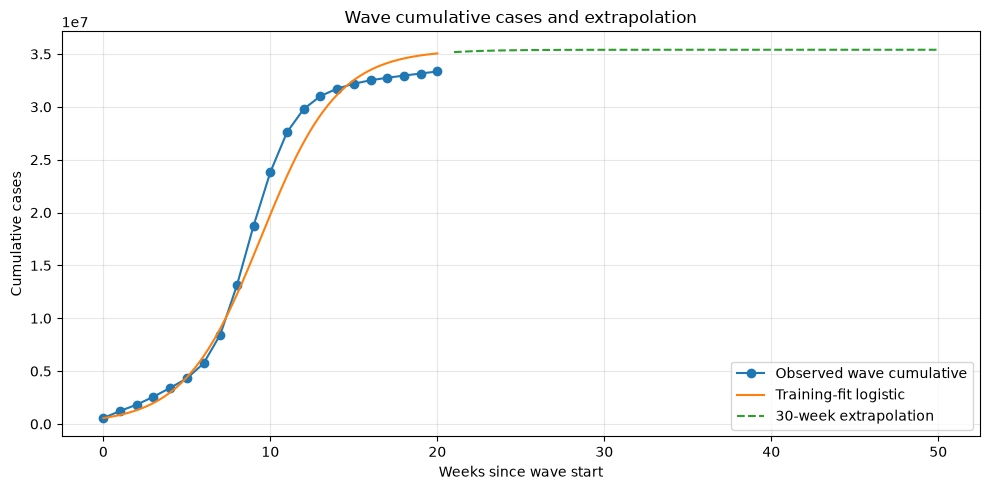

In [7]:
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(t,P,"o-",label="Observed wave cumulative")
ax.plot(tf,logistic(tf,*params),label="Training-fit logistic")
future_t=np.arange(t[-1]+1,t[-1]+31)
ax.plot(future_t,logistic(future_t,*params),"--",label="30-week extrapolation")
ax.set(title="Wave cumulative cases and extrapolation",xlabel="Weeks since wave start",ylabel="Cumulative cases")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout()

## 3. Parameter uncertainty and model caveats
The covariance matrix returned by nonlinear least squares is a local approximation and can be poorly conditioned when the observed wave has not approached a plateau. The carrying-capacity estimate may therefore be extremely large or weakly identified. Do not interpret a numerical fit as evidence that the epidemic obeyed a logistic law.

In [8]:
parameter_table=pd.DataFrame({"parameter":["r (per week)","K (carrying capacity)","P0 (fit initial level)"],"estimate":params,"approx_std_error":np.sqrt(np.maximum(np.diag(cov),0))})
parameter_table

,parameter,estimate,approx_std_error
0,r (per week),4.375169e-01,6.716312e-02
1,K (carrying capacity),3.540266e+07,3.011873e+06
2,P0 (fit initial level),5.571800e+05,2.913950e+05


In [9]:
out=ROOT/"results"; out.mkdir(exist_ok=True)
parameter_table.to_csv(out/f"logistic_parameters_wave_{WAVE_ID}.csv",index=False)
pd.DataFrame([{"wave":WAVE_ID,**metrics}]).to_csv(out/f"logistic_metrics_wave_{WAVE_ID}.csv",index=False)
forecast_table.to_csv(out/f"logistic_forecast_wave_{WAVE_ID}.csv",index=False)
print("Saved outputs under",out)

Saved outputs under c:\Users\tchin\Downloads\COVID19-Logistic-Growth-Project\results
